# Data Structures & Algorithms: Hashing

> **Who is this for:** anyone who uses Python `dict` and `set` every day and wants to know how they achieve O(1) lookups, what can make them slow, and how hashing powers large-scale AI systems (deduplication, feature hashing, caching, sharding). Also for DSA exam and interview preparation.
>
> **What you will learn:**
> - Hash functions: division and multiplication methods, string hashing, what makes a good hash, why Python randomises string hashes (`PYTHONHASHSEED`), hashing vs. encryption
> - Collision resolution, implemented from scratch: **separate chaining** and **open addressing** (linear probing, quadratic probing, double hashing)
> - Load factor and rehashing; measured probe counts vs. the textbook formulas
> - How CPython's `dict` and `set` really work
> - Six classic interview problems solved with hashing
> - Consistent hashing, Bloom filters (with measured false-positive rates), feature hashing and MinHash/LSH for near-duplicate detection
>
> **Prerequisites:** [01 · Complexity and recursion](01_complexity_analysis_and_recursion.ipynb), [02 · Arrays and techniques](02_arrays_strings_and_techniques.ipynb) (prefix sums), [03 · Searching and sorting](03_searching_and_sorting.ipynb) (binary search, `bisect`). Basic probability (what "uniformly random" means) helps; see [probability](../../14_Mathematics/03_probability.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows the "Hashing" section of the GeeksforGeeks DSA tutorial and CLRS chapter 11.

## Explained simply

**Hashing** turns any key (a name, a word, a user ID) into a number that tells you exactly which box to put it in, so later you can go straight to that box instead of searching. This is how Python's `dict` and `set` find things almost instantly, no matter how many items they hold. Sometimes two keys get the same box (a **collision**); a hash table needs a rule for that, like sharing the box or trying the next one. The same trick, turning things into short "fingerprints", is used to spot duplicate documents, check passwords and split data across many servers.

**Everyday examples**
- A **cloakroom**: you get ticket 37 and your coat hangs on hook 37, so nobody has to search all the coats.
- **Library shelves by first letter**: books by authors starting with "M" go to shelf M. Two authors with the same letter share a shelf (a collision), and you only search that one shelf.
- **Fingerprints**: a tiny summary that (almost) uniquely identifies a person, without being the person.

**Tiny example.** Use 10 boxes and the rule "box = number mod 10" (the last digit). Student IDs 1234, 5678 and 9012 go to boxes 4, 8 and 2. To check whether 5678 is enrolled, look only in box 8: one look instead of scanning the whole list. ID 3334 also wants box 4 (a collision), so box 4 now holds two IDs and we check both.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Hash table | a key's number tells you which box it lives in | Python dict/set, caches of LLM answers, database indexes |
| Bloom filter | a tiny bit-sheet that says "definitely not seen" or "probably seen" | web crawlers, spam filters, databases skipping disk reads |
| MinHash / LSH | short fingerprints that are similar when documents are similar | removing near-duplicate web pages from LLM training data |

## Table of contents
1. The idea: direct addressing → hash tables
2. Hash functions: division, multiplication, strings, good properties
3. Python's `hash()`, `PYTHONHASHSEED`, and hashing vs. encryption
4. Separate chaining: a HashMap from scratch
5. Open addressing: linear probing, quadratic probing, double hashing
6. Load factor, probe counts and rehashing (measured vs. theory)
7. How Python's `dict` and `set` work
8. Classic hashing problems
9. Consistent hashing
10. Bloom filters
11. Hashing in AI: feature hashing and MinHash/LSH
12. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import hashlib, zlib, os, subprocess, bisect
from collections import Counter, defaultdict

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. The idea: from direct addressing to hash tables

> 💡 **In plain English:** a hash table turns each key into a box number so you can jump straight to it.

**Intuition.** A cloakroom: you hand in your coat and get ticket number 37; later, ticket 37 takes the attendant straight to hook 37. No searching.

If keys were small integers (0…m−1), we could store each item at `table[key]`: **direct addressing**, O(1) for everything. But real keys are strings, huge IDs or tuples; the universe U of possible keys is enormous.

A **hash table** stores n items in an array of m **buckets/slots** (m ≈ n, much smaller than |U|). A **hash function** h : U → {0, 1, …, m−1} maps each key to a slot index. Since |U| > m, different keys can map to the same slot: a **collision** (pigeonhole principle). A hash table therefore needs (1) a good hash function that spreads keys evenly and (2) a **collision resolution** strategy.

```
key "cat" --h--> 3          slots:  0 [      ]
key "dog" --h--> 6                  1 [      ]
key "emu" --h--> 3  ← collision!    2 [      ]
                                    3 [ cat  ] → emu ?   (where does emu go?)
                                    ...
                                    6 [ dog  ]
```

The **load factor** α = n / m (items per slot) controls performance. With a good hash function and α kept bounded, insert, search and delete take **O(1) on average**.

---
## 2. Hash functions

> 💡 **In plain English:** a hash function is the rule that turns a key into a box number, and a good one spreads keys evenly.

### Division method
**h(k) = k mod m.** Fast, but the choice of m matters. If m = 2ᵖ, h(k) just keeps the lowest p bits of k, so keys that share low bits (e.g. all multiples of 8, like aligned memory addresses or IDs ending in 000) collide massively. **Choose m prime and not close to a power of 2.**

### Multiplication method
**h(k) = ⌊m · frac(k · A)⌋** with a constant 0 < A < 1, where frac(x) = x − ⌊x⌋. Knuth suggests **A = (√5 − 1)/2 ≈ 0.618** (the golden ratio conjugate). The value of m is no longer critical, so m = 2ᵖ is fine and the computation becomes a multiply and a shift on machine words ("Fibonacci hashing").

### Hashing strings
Treat the string as a number in some base: the **polynomial hash** h(s) = (s₀·pⁿ⁻¹ + s₁·pⁿ⁻² + … + sₙ₋₁) mod M, computed with Horner's rule. A naive "sum of character codes" is terrible: every anagram ("listen", "silent") collides.

Hand example, multiplication method with m = 8, k = 21: 21 × 0.618034 = 12.97871 → frac = 0.97871 → ⌊8 × 0.97871⌋ = **7**.

multiplication method, m = 8, k = 21 → 7


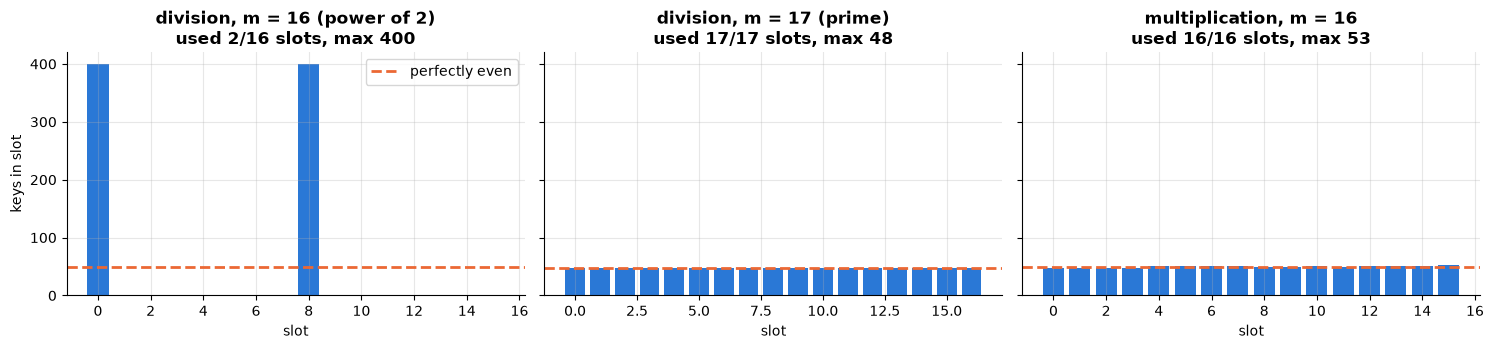

In [2]:
A = (math.sqrt(5) - 1) / 2

def h_div(k, m):
    return k % m

def h_mul(k, m):
    return int(m * ((k * A) % 1.0))           # floor(m * frac(k*A))

print("multiplication method, m = 8, k = 21 →", h_mul(21, 8))
assert h_mul(21, 8) == 7

keys = [8 * i for i in range(1, 801)]         # 800 keys, all multiples of 8 (a common real-world pattern)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for a_, (title, fn, m) in zip(ax, [("division, m = 16 (power of 2)", h_div, 16),
                                   ("division, m = 17 (prime)", h_div, 17),
                                   ("multiplication, m = 16", h_mul, 16)]):
    counts = np.bincount([fn(k, m) for k in keys], minlength=m)
    a_.bar(range(m), counts, color=PALETTE[0])
    a_.axhline(len(keys) / m, color=PALETTE[1], ls="--", label="perfectly even")
    a_.set(title=f"{title}\nused {np.count_nonzero(counts)}/{m} slots, max {counts.max()}", xlabel="slot")
ax[0].set_ylabel("keys in slot"); ax[0].legend()
plt.tight_layout(); plt.show()

**What just happened?** All 800 keys are multiples of 8. With **k mod 16** they land in only **2 of 16 slots** (400 keys each!), because 8i mod 16 is always 0 or 8. With the prime m = 17 they spread almost perfectly, and the multiplication method spreads them well even with m = 16.

In [3]:
from itertools import product

def hash_sum(s, M=1_000_000_007):
    return sum(ord(c) for c in s) % M          # naive: ignores order

def hash_poly(s, p=31, M=1_000_000_007):
    h = 0
    for c in s:
        h = (h * p + ord(c)) % M                # Horner's rule: polynomial in p
    return h

words = ["".join(t) for t in product("abcdefghijklmnopqrstuvwxyz", repeat=3)]   # all 17,576 three-letter strings
print(f"{len(words):,} distinct 3-letter strings")
print(f"  sum-of-codes hash : {len(set(map(hash_sum, words))):>6,} distinct hash values")
print(f"  polynomial hash   : {len(set(map(hash_poly, words))):>6,} distinct hash values")
print("  'listen' vs 'silent':", hash_sum("listen") == hash_sum("silent"), "(sum) |", hash_poly("listen") == hash_poly("silent"), "(poly)")

17,576 distinct 3-letter strings
  sum-of-codes hash :     76 distinct hash values
  polynomial hash   : 17,576 distinct hash values
  'listen' vs 'silent': True (sum) | False (poly)


**What just happened?** The sum-of-codes hash produces only **76** different values for 17,576 strings (the sums range from 3·97 to 3·122), so most strings collide; the polynomial hash gives every string its own value.

**Properties of a good hash function for hash tables:**

| Property | Meaning |
|---|---|
| **Deterministic** | the same key always gives the same hash (within one program run) |
| **Uniform** | keys spread evenly over the slots, even for patterned input |
| **Fast** | O(length of key), a few CPU instructions per byte |
| **Uses the whole key** | every character/bit influences the result (otherwise patterns collide) |

**Cryptographic** hash functions (SHA-256, BLAKE2, SHA-3) additionally need: **preimage resistance** (can't find a key from its hash), **collision resistance** (can't find two keys with the same hash) and the **avalanche effect** (flipping one input bit flips about half the output bits). They are much slower, so hash tables use fast non-cryptographic hashes (SipHash, xxHash, MurmurHash, or simple integer mixing).

> 🎓 **Exam / interview tip:** with **universal hashing** (CLRS 11.3.3) the hash function is chosen at random from a family such as h(k) = ((a·k + b) mod p) mod m, so no fixed input can be bad for every choice: expected O(1) operations for *any* input. We use exactly this family for MinHash in section 11.

---
## 3. Python's `hash()`, `PYTHONHASHSEED`, and hashing vs. encryption

> 💡 **In plain English:** Python scrambles string hashes differently every run for safety, and hashing (one-way) is not encryption (two-way).

- For **integers**, `hash(n)` is n reduced modulo the Mersenne prime 2⁶¹ − 1 (on 64-bit builds), so small ints hash to themselves. Special case: `hash(-1) == -2`, because −1 signals an error inside CPython's C code. Numbers that are equal hash equally: `hash(1) == hash(1.0) == hash(True)`.
- For **str and bytes**, Python uses **SipHash** (SipHash-1-3 by default since Python 3.11) with a secret random key chosen when the interpreter starts. So `hash("cat")` **changes every time you start Python**. This is **hash randomisation**, on by default since Python 3.3.
- **Why?** In 2011 researchers showed that attackers could send web servers thousands of form fields whose names all collide in the hash table, turning O(1) inserts into O(n) and a single request into minutes of CPU time (a **hash-flooding denial-of-service** attack, CVE-2012-1150 for Python). A secret, per-process key makes collisions unpredictable.
- The environment variable **`PYTHONHASHSEED`** fixes the key (an integer) for reproducibility or disables randomisation (`0`).

Consequence: **never store or share the result of `hash()`** (in files, databases, feature vectors or across worker processes). Use a stable hash such as `hashlib` or `zlib.crc32` for that.

In [4]:
print("hash(42) =", hash(42), "| hash(-1) =", hash(-1), "| hash(2**61 - 1) =", hash(2**61 - 1),
      "| hash(1) == hash(1.0) == hash(True):", hash(1) == hash(1.0) == hash(True))
print("sys.hash_info:", sys.hash_info.algorithm, "| modulus = 2**61 - 1:", sys.hash_info.modulus == 2**61 - 1)

def hash_in_new_interpreter(seed):
    """Start a fresh Python process with a given PYTHONHASHSEED and return hash('cat')."""
    env = dict(os.environ)
    if seed is None:
        env.pop("PYTHONHASHSEED", None)          # default: random seed per process
    else:
        env["PYTHONHASHSEED"] = str(seed)
    out = subprocess.run([sys.executable, "-c", "print(hash('cat'))"], capture_output=True, text=True, env=env)
    return int(out.stdout)

rows = [{"PYTHONHASHSEED": str(s), "run": run, "hash('cat')": hash_in_new_interpreter(s)}
        for s in [None, 0, 123] for run in [1, 2]]
df = pd.DataFrame(rows); df["PYTHONHASHSEED"] = df["PYTHONHASHSEED"].replace("None", "(unset → random)")
display(df)
assert rows[2]["hash('cat')"] == rows[3]["hash('cat')"] and rows[4]["hash('cat')"] == rows[5]["hash('cat')"]
assert rows[0]["hash('cat')"] != rows[1]["hash('cat')"]          # two random seeds (equal with prob ~2^-64)
print("stable alternatives:", "crc32('cat') =", zlib.crc32(b"cat"), "| sha256('cat')[:16] =", hashlib.sha256(b"cat").hexdigest()[:16])

hash(42) = 42 | hash(-1) = -2 | hash(2**61 - 1) = 0 | hash(1) == hash(1.0) == hash(True): True
sys.hash_info: siphash13 | modulus = 2**61 - 1: True


,PYTHONHASHSEED,run,hash('cat')
0,(unset → random),1,-7069315891242647622
1,(unset → random),2,-7037506777325868384
2,0,1,692052486964499043
3,0,2,692052486964499043
4,123,1,8145833227370619195
5,123,2,8145833227370619195


stable alternatives: crc32('cat') = 2656977832 | sha256('cat')[:16] = 77af778b51abd4a3


**What just happened?** Each row started a brand-new Python process. With `PYTHONHASHSEED` unset, `hash('cat')` differed between the two runs; with a fixed seed (0 or 123) it was identical across runs. `zlib.crc32` and `hashlib.sha256` are stable everywhere, forever.

### Hashing vs. encryption

| | **Hashing** | **Encryption** |
|---|---|---|
| Purpose | fingerprint / index / integrity check | confidentiality |
| Reversible? | **no** (one-way) | **yes**, with the key |
| Output size | fixed (e.g. 256 bits) | about the size of the input |
| Key needed? | no (except keyed hashes like HMAC, SipHash) | yes |
| Examples | SHA-256, BLAKE2, SipHash, CRC32 | AES, ChaCha20, RSA |

Passwords should be stored with a deliberately **slow, salted** password hash (Argon2, scrypt, bcrypt, PBKDF2), never with plain SHA-256 and never encrypted. Below: the avalanche effect of SHA-256 measured.

In [5]:
def bits_differ(a: bytes, b: bytes) -> int:
    return bin(int.from_bytes(a, "big") ^ int.from_bytes(b, "big")).count("1")

flips = []
for _ in range(500):
    msg = bytearray(random.getrandbits(8) for _ in range(32))
    msg2 = bytearray(msg); msg2[random.randrange(32)] ^= 1 << random.randrange(8)      # flip ONE input bit
    flips.append(bits_differ(hashlib.sha256(msg).digest(), hashlib.sha256(msg2).digest()))
print(f"SHA-256: flipping 1 input bit changes on average {np.mean(flips):.1f} of 256 output bits (ideal: 128), min {min(flips)}, max {max(flips)}")
print(f"Our polynomial hash: 'cat' → {hash_poly('cat')}, 'cau' → {hash_poly('cau')} (neighbouring inputs, neighbouring outputs: fine for tables, useless for security)")

SHA-256: flipping 1 input bit changes on average 128.2 of 256 output bits (ideal: 128), min 102, max 154
Our polynomial hash: 'cat' → 98262, 'cau' → 98263 (neighbouring inputs, neighbouring outputs: fine for tables, useless for security)


**What just happened?** Changing a single input bit flipped about half of SHA-256's 256 output bits (the avalanche effect), so similar inputs give unrelated-looking hashes. Our polynomial hash maps "cat" and "cau" to consecutive numbers: perfectly fine for spreading keys in a table, but trivially predictable, so never use it for security.

---
## 4. Separate chaining

> 💡 **In plain English:** when keys collide, let each box hold a small list of everything that landed there.

**Intuition.** Each hook in the cloakroom can hold a *rack* of coats. If two tickets map to the same hook, both coats hang on that rack.

In **separate chaining** every slot holds a list (a "chain") of the (key, value) pairs that hash there.
```
slot 0: []
slot 1: [("dog", 4)]
slot 2: []
slot 3: [("cat", 1), ("emu", 9)]     ← collision handled by the chain
```
- **insert**: hash, then append to the chain (or update if the key is already there).
- **search / delete**: hash, then scan only that chain.

With simple uniform hashing, a chain has α = n/m items on average: an unsuccessful search costs Θ(1 + α), a successful one Θ(1 + α/2). If we **resize** (double m and re-insert everything) whenever α exceeds a threshold, α stays O(1) and every operation is **O(1) on average** (resizing is amortized, exactly like dynamic arrays in notebook 01). The worst case is O(n), when all keys land in one chain.

In [6]:
class ChainedHashMap:
    """Hash map with separate chaining. Resizes (doubles) when the load factor exceeds max_load."""

    def __init__(self, capacity=8, max_load=0.75, resize=True):
        self.m = capacity
        self.buckets = [[] for _ in range(self.m)]   # one Python list (chain) per slot
        self.n = 0
        self.max_load, self.resize_enabled = max_load, resize
        self.last_probes = 0                          # keys compared in the last lookup

    def _index(self, key):
        return hash(key) % self.m                     # Python's hash, reduced to a slot index

    def put(self, key, value):
        chain = self.buckets[self._index(key)]
        for pair in chain:
            if pair[0] == key:                        # key already present: update in place
                pair[1] = value
                return
        chain.append([key, value])
        self.n += 1
        if self.resize_enabled and self.n / self.m > self.max_load:
            self._rehash(2 * self.m)

    def get(self, key, default=None):
        chain = self.buckets[self._index(key)]
        self.last_probes = 0
        for k, v in chain:
            self.last_probes += 1
            if k == key:
                return v
        return default

    def remove(self, key):
        chain = self.buckets[self._index(key)]
        for i, (k, _) in enumerate(chain):
            if k == key:
                chain[i] = chain[-1]; chain.pop()      # O(1) removal: swap with the last element
                self.n -= 1
                return True
        return False

    def _rehash(self, new_m):
        old_items = [pair for chain in self.buckets for pair in chain]
        self.m = new_m
        self.buckets = [[] for _ in range(self.m)]
        for k, v in old_items:                         # every key gets a new slot: O(n)
            self.buckets[self._index(k)].append([k, v])

    def __contains__(self, key):
        return any(k == key for k, _ in self.buckets[self._index(key)])
    def __len__(self):
        return self.n
    def items(self):
        return [(k, v) for chain in self.buckets for k, v in chain]
    @property
    def load_factor(self):
        return self.n / self.m

def check_against_dict(make_map, n_ops=20_000, key_space=2_000, string_keys=False):
    """Apply the same random put/get/remove operations to our map and to dict; they must agree."""
    ours, ref = make_map(), {}
    for _ in range(n_ops):
        k = random.randrange(key_space)
        if string_keys: k = f"user-{k}"
        op = random.random()
        if op < 0.5:
            v = random.random(); ours.put(k, v); ref[k] = v
        elif op < 0.8:
            assert ours.get(k) == ref.get(k)
        else:
            assert ours.remove(k) == (ref.pop(k, None) is not None)
        assert len(ours) == len(ref)
    assert sorted(ours.items(), key=str) == sorted(ref.items(), key=str)
    return ours

hm = check_against_dict(ChainedHashMap)
check_against_dict(ChainedHashMap, string_keys=True)
print(f"ChainedHashMap agrees with dict on 2 × 20,000 random operations (int and str keys); "
      f"final size {len(hm)}, capacity {hm.m}, load factor {hm.load_factor:.2f}")

ChainedHashMap agrees with dict on 2 × 20,000 random operations (int and str keys); final size 1434, capacity 2048, load factor 0.70


**What just happened?** We ran 20,000 random `put`/`get`/`remove` operations on our chained hash map and on a Python `dict` side by side (twice: integer and string keys) and asserted identical results after every single operation. The final load factor is below 0.75 because the table doubled whenever it got too full.

---
## 5. Open addressing

> 💡 **In plain English:** when keys collide, keep everything in the array itself and walk to another free box by a fixed rule.

**Intuition.** A car park with one car per space: if your space is taken, you try the next space according to a fixed rule until you find a free one.

In **open addressing** all items live directly in the slot array (no chains). On a collision we **probe** a sequence of slots h(k, 0), h(k, 1), h(k, 2), … until we find the key or an empty slot. α must stay **< 1**.

| Probing | Probe sequence | Pros / cons |
|---|---|---|
| **Linear** | (h(k) + i) mod m | cache-friendly, but suffers **primary clustering**: long runs of occupied slots grow and merge |
| **Quadratic** | (h(k) + c₁i + c₂i²) mod m; we use the triangular numbers i(i+1)/2, which visit every slot when m is a power of 2 | breaks primary clustering; keys with the same h(k) still share a sequence (**secondary clustering**) |
| **Double hashing** | (h₁(k) + i·h₂(k)) mod m, with h₂(k) odd so that it is coprime with m = 2ᵖ | different keys get different step sizes: closest to ideal "uniform hashing" |

Hand example, m = 8, linear probing, inserting keys whose home slots are 3, 3, 4, 3:
```
insert A (home 3): slot 3                         [ . . . A . . . . ]
insert B (home 3): 3 taken → 4                    [ . . . A B . . . ]
insert C (home 4): 4 taken → 5                    [ . . . A B C . . ]
insert D (home 3): 3, 4, 5 taken → 6  (4 probes)  [ . . . A B C D . ]   ← a cluster forms
```
**Deletion needs tombstones.** If we deleted B by simply emptying slot 4, a later search for C (home 4, stored at 5) or for D (home 3, stored at 6) would reach the empty slot 4, stop, and wrongly report "not found". So deletion leaves a **tombstone** (DELETED marker): searches skip over it, inserts may reuse it.

Our hash for open addressing is the **multiplication method on 64-bit integers** (Fibonacci hashing): multiply by 2⁶⁴/φ and keep the top p bits, for m = 2ᵖ.

In [7]:
EMPTY, DELETED = object(), object()          # unique sentinel objects
MASK64 = (1 << 64) - 1
GOLDEN = 11400714819323198485                 # ≈ 2^64 / φ (multiplication method constant)
GOLDEN2 = 14029467366897019727                # another odd constant for the second hash

class OpenAddressingHashMap:
    """Open addressing with linear, quadratic (triangular) or double-hashing probes. m is a power of 2."""

    def __init__(self, capacity=8, probing="linear", max_load=0.5, resize=True):
        assert capacity & (capacity - 1) == 0, "capacity must be a power of 2"
        self.m, self.p = capacity, capacity.bit_length() - 1
        self.keys = [EMPTY] * capacity
        self.vals = [None] * capacity
        self.n = self.tombstones = 0
        self.probing, self.max_load, self.resize_enabled = probing, max_load, resize
        self.last_probes = 0

    def _probe_sequence(self, key):
        x = hash(key) & MASK64
        h1 = ((x * GOLDEN) & MASK64) >> (64 - self.p) if self.p else 0      # top p bits
        if self.probing == "double":
            step = (((x * GOLDEN2) & MASK64) >> (64 - self.p)) | 1 if self.p else 1   # odd step
        for i in range(self.m):
            if self.probing == "linear":
                yield (h1 + i) % self.m
            elif self.probing == "quadratic":
                yield (h1 + i * (i + 1) // 2) % self.m                      # 0, 1, 3, 6, 10, ...
            else:
                yield (h1 + i * step) % self.m

    def _find_slot(self, key):
        """Return (index of key or None, first free slot usable for insertion)."""
        first_free = None
        self.last_probes = 0
        for idx in self._probe_sequence(key):
            self.last_probes += 1
            k = self.keys[idx]
            if k is EMPTY:                                   # end of the probe chain
                return None, (first_free if first_free is not None else idx)
            if k is DELETED:
                if first_free is None: first_free = idx      # remember a reusable tombstone
            elif k == key:
                return idx, None
        return None, first_free                              # table scanned completely

    def put(self, key, value):
        found, free = self._find_slot(key)
        if found is not None:
            self.vals[found] = value
            return
        if self.keys[free] is DELETED:
            self.tombstones -= 1
        self.keys[free], self.vals[free] = key, value
        self.n += 1
        if self.resize_enabled and (self.n + self.tombstones) / self.m > self.max_load:
            self._rehash(2 * self.m if self.n / self.m > self.max_load / 2 else self.m)

    def get(self, key, default=None):
        found, _ = self._find_slot(key)
        return self.vals[found] if found is not None else default

    def remove(self, key):
        found, _ = self._find_slot(key)
        if found is None:
            return False
        self.keys[found], self.vals[found] = DELETED, None    # tombstone, NOT empty
        self.n -= 1; self.tombstones += 1
        return True

    def _rehash(self, new_m):
        old = [(k, v) for k, v in zip(self.keys, self.vals) if k is not EMPTY and k is not DELETED]
        self.__init__(new_m, self.probing, self.max_load, self.resize_enabled)   # fresh table (drops tombstones)
        for k, v in old:
            self.put(k, v)

    def __contains__(self, key): return self._find_slot(key)[0] is not None
    def __len__(self): return self.n
    def items(self): return [(k, v) for k, v in zip(self.keys, self.vals) if k is not EMPTY and k is not DELETED]

for probing in ["linear", "quadratic", "double"]:
    check_against_dict(lambda: OpenAddressingHashMap(probing=probing))
    check_against_dict(lambda: OpenAddressingHashMap(probing=probing), string_keys=True)
    # every probe sequence must visit all m slots exactly once (so inserts never fail while a slot is free)
    t = OpenAddressingHashMap(capacity=64, probing=probing)
    assert all(sorted(t._probe_sequence(random.random())) == list(range(64)) for _ in range(200))
print("Open addressing (linear, quadratic, double) agrees with dict on random put/get/remove sequences,")
print("and every probe sequence is a permutation of all slots.")

Open addressing (linear, quadratic, double) agrees with dict on random put/get/remove sequences,
and every probe sequence is a permutation of all slots.


**What just happened?** All three probing variants passed the same 20,000-operation random comparison against `dict` (with deletions, so tombstones were exercised), for both integer and string keys. We also checked that each probe sequence visits all 64 slots exactly once: true for linear probing trivially, for triangular-number quadratic probing because m is a power of 2, and for double hashing because the step is odd (coprime with 2ᵖ).

> ⚠️ **Common mistake:** quadratic probing with i² and an arbitrary m may visit only about half of the slots and then fail to insert into a table that still has free space. Use triangular numbers with m = 2ᵖ, or i² with a prime m and α ≤ ½.

---
## 6. Load factor, probe counts and rehashing

> 💡 **In plain English:** the fuller the table, the more boxes you must check, so tables grow before they get too full.

How many slots (or chain entries) does a lookup examine at load factor α? The classic results (Knuth; CLRS 11.4) assume a random-looking hash:

| Scheme | Successful search | Unsuccessful search |
|---|---|---|
| Separate chaining (entries compared) | 1 + α/2 | α |
| Linear probing (slots probed) | ½ (1 + 1/(1−α)) | ½ (1 + 1/(1−α)²) |
| Uniform hashing ≈ double hashing | (1/α) ln(1/(1−α)) | 1/(1−α) |

At α = 0.5 linear probing needs about 1.5 / 2.5 probes; at α = 0.9 about 5.5 / 50.5. Let's measure all four schemes on the same random keys in fixed-size tables (resizing disabled) and compare with the formulas.

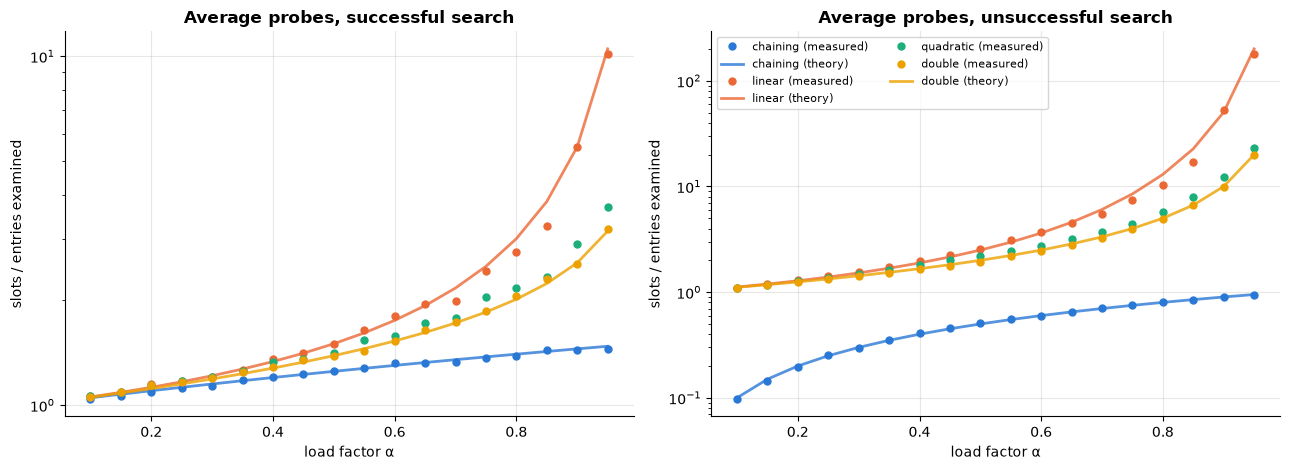

,α = 0.5,α = 0.9,theory α=0.5,theory α=0.9
chaining succ,1.26,1.44,1.25,1.45
chaining unsucc,0.51,0.89,0.5,0.9
linear succ,1.50,5.51,1.5,5.5
linear unsucc,2.59,53.39,2.5,50.5
quadratic succ,1.41,2.89,–,–
quadratic unsucc,2.20,12.16,–,–
double succ,1.38,2.54,1.39,2.56
double unsucc,1.95,9.87,2.0,10.0


In [8]:
M = 4096
alphas = np.round(np.arange(0.1, 0.951, 0.05), 2)
keys_all = random.sample(range(1, 2**62), int(0.95 * M) + 1)
absent = random.sample(range(2**62, 2**63), 2000)          # keys that are never inserted

def measure(table, inserted, absent_keys, sample=1500):
    s = [ (table.get(k), table.last_probes)[1] for k in random.sample(inserted, min(sample, len(inserted)))]
    u = [ (table.get(k), table.last_probes)[1] for k in absent_keys]
    return np.mean(s), np.mean(u)

results = {}
schemes = {"chaining":  lambda: ChainedHashMap(capacity=M, resize=False),
           "linear":    lambda: OpenAddressingHashMap(M, "linear", resize=False),
           "quadratic": lambda: OpenAddressingHashMap(M, "quadratic", resize=False),
           "double":    lambda: OpenAddressingHashMap(M, "double", resize=False)}
for name, make in schemes.items():
    table, inserted, rows = make(), [], []
    for a in alphas:
        while len(inserted) < int(a * M):                    # fill up to load factor a
            k = keys_all[len(inserted)]; table.put(k, True); inserted.append(k)
        rows.append(measure(table, inserted, absent))
    results[name] = np.array(rows)

theory = {
    "chaining": (1 + alphas / 2, alphas),
    "linear":   (0.5 * (1 + 1 / (1 - alphas)), 0.5 * (1 + 1 / (1 - alphas) ** 2)),
    "double":   ((1 / alphas) * np.log(1 / (1 - alphas)), 1 / (1 - alphas)),
}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for j, title in enumerate(["successful search", "unsuccessful search"]):
    for (name, data), col in zip(results.items(), PALETTE):
        ax[j].plot(alphas, data[:, j], "o", ms=5, color=col, label=f"{name} (measured)")
        if name in theory:
            ax[j].plot(alphas, theory[name][j], "-", color=col, alpha=0.8, label=f"{name} (theory)")
    ax[j].set(title=f"Average probes, {title}", xlabel="load factor α", ylabel="slots / entries examined", yscale="log")
ax[1].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

tab = pd.DataFrame({f"{n} {kind}": results[n][[8, 16], j].round(2)
                    for n in results for j, kind in enumerate(["succ", "unsucc"])}, index=["α = 0.5", "α = 0.9"]).T
tab["theory α=0.5"] = [*(np.round([1 + 0.25, 0.5], 2)), *(np.round([1.5, 2.5], 2)), "–", "–", *(np.round([2 * math.log(2), 2.0], 2))]
tab["theory α=0.9"] = [*(np.round([1.45, 0.9], 2)), *(np.round([5.5, 50.5], 2)), "–", "–", *(np.round([math.log(10) / 0.9, 10.0], 2))]
display(tab)

**What just happened?** Measured averages (dots) follow the theoretical curves (lines) closely:
- **Chaining** degrades gently: even at α = 0.95 a lookup compares only about 1.5 entries.
- **Linear probing** is great at α ≤ 0.5 but explodes as α → 1, especially for *unsuccessful* searches (tens of probes at α = 0.9), because of primary clustering.
- **Double hashing** tracks the uniform-hashing formula 1/(1−α); **quadratic probing** sits between linear and double hashing.

That is why open-addressing tables keep α low (CPython's dict ≤ 2/3), while chained tables tolerate α around 1 (Java's HashMap resizes at 0.75).

### Rehashing
When α passes the threshold we allocate a table twice as large and **re-insert every key** (their slots change because h depends on m). One resize costs O(n), but doubling makes it **O(1) amortized** per insert (same argument as the dynamic array in notebook 01).

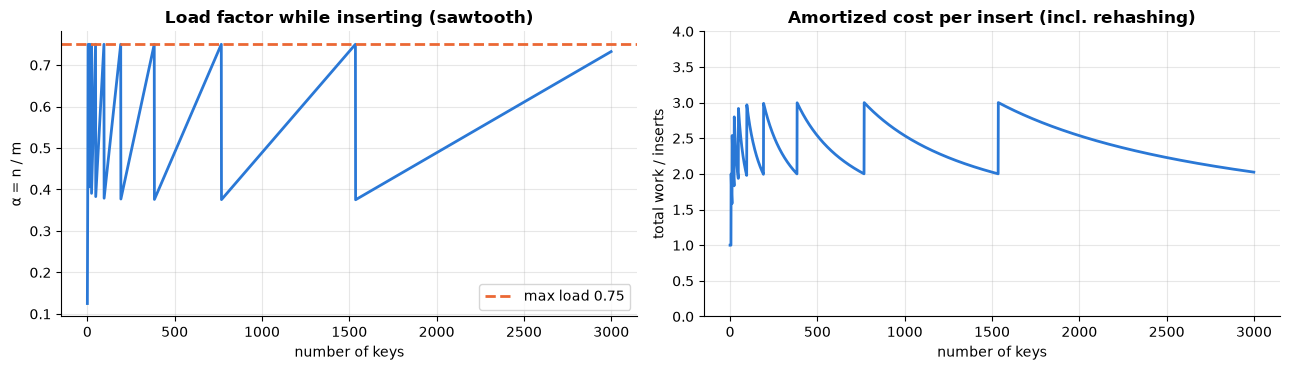

resizes happened at sizes: [8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096] | amortized cost at the end: 2.02


In [9]:
hm = ChainedHashMap(capacity=8, max_load=0.75)
loads, caps, costs = [], [], []
for i in range(3000):
    before = hm.m
    hm.put(f"key-{i}", i)
    costs.append(1 + (len(hm) if hm.m != before else 0))       # a resize re-inserts every key
    loads.append(hm.load_factor); caps.append(hm.m)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(loads, color=PALETTE[0]); ax[0].axhline(0.75, ls="--", color=PALETTE[1], label="max load 0.75")
ax[0].set(title="Load factor while inserting (sawtooth)", xlabel="number of keys", ylabel="α = n / m"); ax[0].legend()
ax[1].plot(np.cumsum(costs) / np.arange(1, len(costs) + 1), color=PALETTE[0])
ax[1].set(title="Amortized cost per insert (incl. rehashing)", xlabel="number of keys", ylabel="total work / inserts", ylim=(0, 4))
plt.tight_layout(); plt.show()
print("resizes happened at sizes:", sorted({c for c in caps}), "| amortized cost at the end:", round(sum(costs) / len(costs), 2))

**What just happened?** The load factor climbs to 0.75, the table doubles, α drops to about 0.375, and the cycle repeats: a sawtooth. The capacity went 8 → 16 → … → 4096. Counting each re-inserted key as one unit of work, the average cost per insert stays below 3: O(1) amortized.

---
## 7. How Python's `dict` and `set` work

> 💡 **In plain English:** Python's dict and set are carefully tuned hash tables, and keys must be unchangeable (hashable).

**`dict` (CPython 3.6+, "compact dict")**
- **Open addressing**, not chaining. The probe sequence is pseudo-random and uses all bits of the hash: `j = (5*j + 1 + perturb) mod 2^k`, then `perturb >>= 5`. Early probes are driven by the high bits of the hash, later ones by the recurrence alone, which eventually visits every slot.
- Two arrays: a small **sparse index table** (1, 2, 4 or 8 bytes per slot) that stores positions into a **dense entries array** of `(hash, key, value)` in insertion order. This saves memory (the big entries array has no holes) and makes iteration fast.
- Because entries are appended in order, **dicts preserve insertion order**; this became a language guarantee in Python 3.7.
- The table is kept **at most 2/3 full** (usable fraction); when full it is resized to a larger power of two. Deleted keys leave a **dummy** marker in the index table (a tombstone) until the next resize.
- The stored hash is compared before the (possibly expensive) `==` on keys.

**`set`**
- Also open addressing with the same perturbation idea, but it first checks a few **adjacent slots** (linear probing, cache-friendly) before jumping. It stores only (hash, key), has **no ordering guarantee**, and resizes at about 60% full.

**Rules for keys**: an object is hashable if it has a `__hash__` that never changes during its lifetime and **a == b implies hash(a) == hash(b)**. Built-in mutable containers (`list`, `dict`, `set`) are unhashable; `tuple` and `frozenset` are hashable if their contents are.

In [10]:
d = {}
sizes = []
for i in range(30):
    d[i] = i
    sizes.append(sys.getsizeof(d))
jumps = [(i + 1, s) for i, (s, prev) in enumerate(zip(sizes, [0] + sizes[:-1])) if s != prev]
print("dict memory jumps at (number of keys → bytes):", jumps)

print("insertion order kept:", list({"z": 1, "a": 2, "m": 3}))
print("1, 1.0 and True are the SAME key:", {1: "int", 1.0: "float", True: "bool"})
try:
    {[1, 2]: "list as key"}
except TypeError as e:
    print("TypeError:", e)
print("tuples and frozensets are fine:", {(1, 2): "tuple", frozenset({3}): "frozenset"})

dict memory jumps at (number of keys → bytes): [(1, 224), (6, 352), (11, 632), (22, 1168)]
insertion order kept: ['z', 'a', 'm']
1, 1.0 and True are the SAME key: {1: 'bool'}
TypeError: unhashable type: 'list'
tuples and frozensets are fine: {(1, 2): 'tuple', frozenset({3}): 'frozenset'}


**What just happened?** `sys.getsizeof` jumps at a few sizes only: the table is resized to a bigger power of two when it reaches its 2/3 usable limit (exact byte counts vary between Python versions). Keys come back in insertion order. Because `1 == 1.0 == True` and they hash equally, the three "different" keys collapse into one entry (the first key object is kept, the last value wins). A list key raises `TypeError: unhashable type`.

### When O(1) becomes O(n): a bad `__hash__`
If every key has the same hash, every insert must probe past all previous keys: building the dict becomes O(n²). This is exactly what hash-flooding attacks exploit.

In [11]:
class BadKey:
    def __init__(self, v): self.v = v
    def __hash__(self): return 42                    # every key collides!
    def __eq__(self, other): return self.v == other.v

class GoodKey(BadKey):
    def __hash__(self): return hash(self.v)

rows = []
for n in [250, 500, 1000, 2000]:
    bad, good = [BadKey(i) for i in range(n)], [GoodKey(i) for i in range(n)]
    tb = min(timeit.repeat(lambda: {k: 1 for k in bad}, number=1, repeat=3))
    tg = min(timeit.repeat(lambda: {k: 1 for k in good}, number=1, repeat=3))
    rows.append({"n": n, "good hash (ms)": round(tg * 1000, 2), "constant hash (ms)": round(tb * 1000, 1), "slowdown ×": round(tb / tg)})
display(pd.DataFrame(rows))

,n,good hash (ms),constant hash (ms),slowdown ×
0,250,0.07,13.0,175
1,500,0.16,81.7,496
2,1000,0.35,357.6,1020
3,2000,0.68,877.8,1297


**What just happened?** With a proper hash, building the dict grows linearly. With a constant hash, the time grows much faster than n (O(n²) total, O(n) per insert: doubling n should roughly quadruple the time, although small timings on a busy computer are noisy) and the gap reaches hundreds of times at n = 2000. Always derive `__hash__` from the same fields used in `__eq__` (e.g. `return hash((self.x, self.y))`); `@dataclass(frozen=True)` does this for you.

---
## 8. Classic hashing problems

> 💡 **In plain English:** "Have I seen this before?" and "how many times?" become instant questions with a hash map.

Hashing turns "have I seen this before?" and "how many times?" into O(1) questions. Each problem below has a brute-force version and a hash-based version, checked against each other on random inputs.

| Problem | Brute force | With hashing |
|---|---|---|
| **Two-sum**: indices i < j with a[i] + a[j] = target | all pairs, O(n²) | dict value → index, O(n) |
| **Frequency counting** | count each value by rescanning, O(n²) | dict / `Counter`, O(n) |
| **Group anagrams** | compare every pair of words, O(n²·L log L) | dict keyed by sorted letters or letter counts, O(n·L) with counts |
| **Longest consecutive sequence** (e.g. [100, 4, 200, 1, 3, 2] → 4) | sort, O(n log n) | set; start counting only at sequence starts, O(n) |
| **Subarray sum = k** | all subarrays, O(n²) | prefix sums + dict of counts, O(n) (notebook 02) |
| **First non-repeating character** | for each char, count it, O(n²) | count once, then scan, O(n) |

In [12]:
# ---- 1. two-sum
def two_sum_brute(a, target):
    for i in range(len(a)):
        for j in range(i + 1, len(a)):
            if a[i] + a[j] == target:
                return True
    return False

def two_sum(a, target):
    """Return (i, j), i < j, with a[i] + a[j] == target, or None. One pass, O(n)."""
    seen = {}                                   # value -> index where we saw it
    for j, x in enumerate(a):
        if target - x in seen:                  # the complement appeared earlier
            return (seen[target - x], j)
        seen[x] = j
    return None

# ---- 2. frequency counting
def freq_brute(a):
    return {x: a.count(x) for x in a}           # a.count is O(n) → O(n^2)

def freq(a):
    counts = {}
    for x in a:
        counts[x] = counts.get(x, 0) + 1
    return counts

# ---- 3. group anagrams
def group_anagrams_brute(words):
    groups = []
    for w in words:
        for g in groups:
            if sorted(g[0]) == sorted(w):
                g.append(w); break
        else:
            groups.append([w])
    return groups

def group_anagrams(words):
    groups = defaultdict(list)
    for w in words:
        signature = [0] * 26                    # letter counts: an O(L) key, no sorting
        for c in w:
            signature[ord(c) - 97] += 1
        groups[tuple(signature)].append(w)      # tuple: hashable
    return list(groups.values())

def same_groups(g1, g2):
    return sorted(map(sorted, g1)) == sorted(map(sorted, g2))

# ---- 4. longest consecutive sequence
def longest_consecutive_brute(a):
    if not a: return 0
    s = sorted(set(a)); best = cur = 1
    for x, y in zip(s, s[1:]):
        cur = cur + 1 if y == x + 1 else 1
        best = max(best, cur)
    return best

def longest_consecutive(a):
    s, best = set(a), 0
    for x in s:
        if x - 1 not in s:                      # x starts a sequence
            y = x
            while y + 1 in s:                   # each element is visited once overall
                y += 1
            best = max(best, y - x + 1)
    return best

# ---- 5. subarray sum = k (count), recap from notebook 02
def subarray_sum_k_brute(a, k):
    return sum(sum(a[i:j]) == k for i in range(len(a)) for j in range(i + 1, len(a) + 1))

def subarray_sum_k(a, k):
    seen, prefix, count = {0: 1}, 0, 0
    for x in a:
        prefix += x
        count += seen.get(prefix - k, 0)
        seen[prefix] = seen.get(prefix, 0) + 1
    return count

# ---- 6. first non-repeating character
def first_unique_brute(s):
    for i, c in enumerate(s):
        if s.count(c) == 1:
            return i
    return -1

def first_unique(s):
    counts = Counter(s)                          # pass 1: count
    for i, c in enumerate(s):                    # pass 2: first with count 1
        if counts[c] == 1:
            return i
    return -1

print("two_sum([2, 7, 11, 15], 9) =", two_sum([2, 7, 11, 15], 9))
print("group_anagrams:", group_anagrams(["eat", "tea", "tan", "ate", "nat", "bat"]))
print("longest_consecutive([100, 4, 200, 1, 3, 2]) =", longest_consecutive([100, 4, 200, 1, 3, 2]))
print("first_unique('leetcode') =", first_unique("leetcode"), "| first_unique('aabb') =", first_unique("aabb"))

for _ in range(2000):
    a = [random.randint(-10, 10) for _ in range(random.randint(0, 14))]
    t = random.randint(-15, 15)
    r = two_sum(a, t)
    assert (r is not None) == two_sum_brute(a, t) and (r is None or (r[0] < r[1] and a[r[0]] + a[r[1]] == t))
    assert freq(a) == freq_brute(a) == dict(Counter(a))
    assert longest_consecutive(a) == longest_consecutive_brute(a)
    assert subarray_sum_k(a, t % 7) == subarray_sum_k_brute(a, t % 7)
    words = ["".join(random.choices("abc", k=random.randint(1, 3))) for _ in range(random.randint(0, 10))]
    assert same_groups(group_anagrams(words), group_anagrams_brute(words))
    s = "".join(random.choices("abcd", k=random.randint(0, 10)))
    assert first_unique(s) == first_unique_brute(s)
print("2000 random tests passed for all six problems (hash-based == brute force)")

two_sum([2, 7, 11, 15], 9) = (0, 1)
group_anagrams: [['eat', 'tea', 'ate'], ['tan', 'nat'], ['bat']]
longest_consecutive([100, 4, 200, 1, 3, 2]) = 4
first_unique('leetcode') = 0 | first_unique('aabb') = -1


2000 random tests passed for all six problems (hash-based == brute force)


**What just happened?** Each hash-based solution matched its brute-force twin on 2000 random inputs. A few details worth noticing:
- In **two-sum** we check for the complement *before* inserting the current element, so an element is never paired with itself.
- In **group anagrams** the key must be hashable, so the count list is converted to a `tuple`.
- **Longest consecutive sequence** looks like it has a nested loop, but the inner `while` only runs from sequence starts, so every number is visited at most twice: O(n) total.

---
## 9. Consistent hashing

> 💡 **In plain English:** place servers and keys on a circle so adding a server only moves a small share of the keys.

**Problem.** A cache or database is split over N servers ("shards"). The obvious rule `server = hash(key) mod N` breaks badly when N changes: going from 4 to 5 servers moves about **80%** of all keys (a key stays only if hash mod 4 == hash mod 5).

**Consistent hashing** (Karger et al., 1997) places both servers and keys on a **ring** of hash values [0, 2³²). Each key belongs to the first server clockwise from it. Adding a server only takes over the keys between it and its predecessor: about **1/(N+1)** of the keys move. Each server is placed at many points (**virtual nodes**) so the load is balanced. Used in Amazon Dynamo/Cassandra, CDNs, and load balancers that route requests to model-serving replicas.
```
          0
     S1 •    • k1 → S2 (next server clockwise)
   k3 •        • S2
     S3 •    • k2 → S3
         2^32
```

In [13]:
def stable_hash32(s):
    return int.from_bytes(hashlib.md5(s.encode()).digest()[:4], "big")    # stable across runs (unlike hash())

class ConsistentHashRing:
    def __init__(self, nodes=(), vnodes=100):
        self.vnodes, self.ring = vnodes, []                                 # sorted list of (position, node)
        for n in nodes:
            self.add(n)
    def add(self, node):
        for v in range(self.vnodes):
            bisect.insort(self.ring, (stable_hash32(f"{node}#{v}"), node))
    def remove(self, node):
        self.ring = [(p, n) for p, n in self.ring if n != node]
    def get(self, key):
        i = bisect.bisect_right(self.ring, (stable_hash32(key), chr(0x10FFFF)))   # first point clockwise
        return self.ring[i % len(self.ring)][1]                             # wrap around the ring

keys = [f"user:{i}" for i in range(20_000)]
nodes4 = [f"server{i}" for i in range(4)]

mod4 = {k: stable_hash32(k) % 4 for k in keys}
mod5 = {k: stable_hash32(k) % 5 for k in keys}
moved_mod = np.mean([mod4[k] != mod5[k] for k in keys])

ring = ConsistentHashRing(nodes4, vnodes=100)
before = {k: ring.get(k) for k in keys}
ring.add("server4")
after = {k: ring.get(k) for k in keys}
moved_ring = np.mean([before[k] != after[k] for k in keys])
assert all(after[k] == "server4" for k in keys if before[k] != after[k])    # keys only move TO the new server
print(f"adding a 5th server moves: mod-N {moved_mod:.1%} of keys | consistent hashing {moved_ring:.1%} (ideal 1/5 = 20%)")

for v in [1, 10, 100]:
    r = ConsistentHashRing(nodes4, vnodes=v)
    load = Counter(r.get(k) for k in keys)
    print(f"vnodes = {v:>3}: keys per server = {sorted(load.values())}  (max/mean = {max(load.values()) / (len(keys) / 4):.2f})")

adding a 5th server moves: mod-N 79.7% of keys | consistent hashing 22.4% (ideal 1/5 = 20%)
vnodes =   1: keys per server = [1975, 4082, 5459, 8484]  (max/mean = 1.70)


vnodes =  10: keys per server = [3474, 3966, 5982, 6578]  (max/mean = 1.32)


vnodes = 100: keys per server = [4476, 4931, 5157, 5436]  (max/mean = 1.09)


**What just happened?** Adding a fifth server to a mod-N scheme moved about 80% of the keys (cache misses everywhere), while the ring moved only about 20%, and every moved key went *to* the new server, never between old ones. With 1 virtual node per server the load is very uneven; with 100 virtual nodes each server gets close to a quarter of the keys.

---
## 10. Bloom filters

> 💡 **In plain English:** a Bloom filter remembers a huge set using a few bits per item, at the price of rare false "yes" answers.

**Problem.** Answer "have I seen this item?" for billions of items with very little memory, accepting a small chance of a wrong "yes".

A **Bloom filter** (Bloom, 1970) is a bit array of m bits plus k hash functions.
- **add(x)**: set the k bits h₁(x), …, hₖ(x) to 1.
- **query(x)**: if *any* of the k bits is 0 → **definitely not present**; if all are 1 → **probably present**.

There are **no false negatives**, only **false positives** (all k bits happened to be set by other items). You cannot delete items (clearing a bit might affect others; *counting* Bloom filters fix that).

**False-positive rate** after inserting n items: each bit is still 0 with probability (1 − 1/m)^(kn) ≈ e^(−kn/m), so

**p ≈ (1 − e^(−kn/m))^k**, minimised at **k = (m/n) ln 2**, where p ≈ 0.6185^(m/n). For p = 1% you need only about **9.6 bits per item**, regardless of how large the items are.

We generate the k hash positions cheaply with **double hashing** (Kirsch & Mitzenmacher, 2006): gᵢ(x) = h₁(x) + i·h₂(x) mod m, from one BLAKE2b digest.

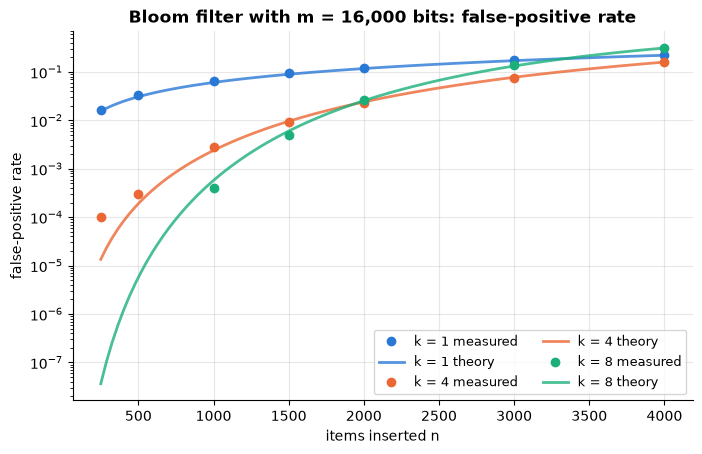

n = 2000, m/n = 8 bits per item → optimal k = 5.5
  k = 1: measured FPR = 0.1219 | theory = 0.1175
  k = 4: measured FPR = 0.0232 | theory = 0.0240
  k = 8: measured FPR = 0.0259 | theory = 0.0255
memory for 4000 strings: Python set ≈ 330 KiB | Bloom filter = 2.0 KiB


In [14]:
class BloomFilter:
    def __init__(self, m_bits, k):
        self.m, self.k = m_bits, k
        self.bits = bytearray((m_bits + 7) // 8)          # m bits packed into bytes
    def _positions(self, item):
        d = hashlib.blake2b(item.encode(), digest_size=16).digest()
        h1, h2 = int.from_bytes(d[:8], "little"), int.from_bytes(d[8:], "little") | 1
        return [(h1 + i * h2) % self.m for i in range(self.k)]
    def add(self, item):
        for p in self._positions(item):
            self.bits[p >> 3] |= 1 << (p & 7)              # set bit p
    def __contains__(self, item):
        return all(self.bits[p >> 3] >> (p & 7) & 1 for p in self._positions(item))

def theory_fpr(m, n, k):
    return (1 - math.exp(-k * n / m)) ** k

m = 16_000
members = [f"member-{i}" for i in range(4000)]
non_members = [f"stranger-{i}" for i in range(10_000)]
ns = [250, 500, 1000, 1500, 2000, 3000, 4000]
fig, ax = plt.subplots(figsize=(8, 4.8))
measured = {}
for k, col in zip([1, 4, 8], PALETTE):
    bf, fprs, added = BloomFilter(m, k), [], 0
    for n in ns:
        while added < n:
            bf.add(members[added]); added += 1
        assert all(x in bf for x in members[:n])          # NO false negatives, ever
        fprs.append(np.mean([x in bf for x in non_members]))
    measured[k] = fprs
    ax.plot(ns, fprs, "o", color=col, label=f"k = {k} measured")
    nn = np.linspace(ns[0], ns[-1], 100)
    ax.plot(nn, [theory_fpr(m, v, k) for v in nn], "-", color=col, alpha=0.8, label=f"k = {k} theory")
ax.set(title=f"Bloom filter with m = {m:,} bits: false-positive rate", xlabel="items inserted n", ylabel="false-positive rate", yscale="log")
ax.legend(ncol=2, fontsize=9); plt.show()

n = 2000
print(f"n = {n}, m/n = {m / n:.0f} bits per item → optimal k = {m / n * math.log(2):.1f}")
for k in [1, 4, 8]:
    print(f"  k = {k}: measured FPR = {measured[k][ns.index(n)]:.4f} | theory = {theory_fpr(m, n, k):.4f}")
set_bytes = sys.getsizeof(set(members)) + sum(sys.getsizeof(x) for x in members)
print(f"memory for 4000 strings: Python set ≈ {set_bytes / 1024:.0f} KiB | Bloom filter = {len(bf.bits) / 1024:.1f} KiB")

**What just happened?** We inserted up to 4000 strings into a 16,000-bit (2 KB) filter and queried 10,000 strings that were never inserted. The measured false-positive rates (dots) sit on the theoretical curves (lines) for k = 1, 4 and 8, and every inserted item was always found (no false negatives). (For very small n the true rate is below 1/10,000, the smallest non-zero rate 10,000 queries can measure, so those dots are noisy, and a measured rate of 0 cannot be drawn on the log scale.) At n = 2000 (8 bits per item) the optimal k is about 5.5; k = 4 and k = 8 both beat k = 1 by roughly a factor of 4–5, but once the filter gets fuller (n = 4000, 4 bits per item) too many hash functions hurt, and k = 8 becomes worse than k = 4 (and even than k = 1). The filter uses a few KB where a Python set of the same strings needs hundreds of KB.

> 🎓 **Exam / interview tip:** "Can a Bloom filter return a false negative?" No. "Can you delete from it?" Not from the standard version. "How do you size it?" m = −n ln p / (ln 2)², k = (m/n) ln 2.

---
## 11. 🔗 Hashing in AI

> 💡 **In plain English:** hashing lets ML handle huge vocabularies (feature hashing) and find near-duplicate documents (MinHash/LSH).

### Feature hashing (the "hashing trick")
Text models need fixed-length vectors, but vocabularies are huge and keep growing. **Feature hashing** (Weinberger et al., 2009) skips the vocabulary dictionary entirely: index = h(token) mod D, and a second hash bit chooses a sign ±1 so that collisions cancel out on average (inner products are preserved in expectation). Memory is fixed at D, new words need no retraining of the vocabulary, and it works in streaming settings. scikit-learn's `HashingVectorizer` and Vowpal Wabbit use it. (Note: we must use a **stable** hash such as CRC32 or MurmurHash, not Python's randomised `hash()`, or the features would change between runs!) See [feature engineering](../../03_Machine_Learning/05_feature_engineering/01_feature_engineering.ipynb).

In [15]:
docs = [
    "the cat sat on the mat",
    "the dog sat on the log",
    "a cat and a dog played in the garden",
    "neural networks learn representations of text",
    "transformers learn contextual representations of words",
    "the stock market fell sharply on monday",
]

def hashed_vector(text, D):
    """Signed feature hashing with a STABLE hash (CRC32)."""
    v = np.zeros(D)
    for tok in text.split():
        h = zlib.crc32(tok.encode())
        idx = h % D                                     # which feature
        sign = 1 if (h >> 31) & 1 == 0 else -1          # a different bit gives the sign
        v[idx] += sign
    return v

vocab = sorted({t for d in docs for t in d.split()})
def exact_vector(text):
    return np.array([text.split().count(w) for w in vocab], dtype=float)

def cos(a, b):
    na, nb_ = np.linalg.norm(a), np.linalg.norm(b)
    return 0.0 if na == 0 or nb_ == 0 else a @ b / (na * nb_)

pairs = [(i, j) for i in range(len(docs)) for j in range(i + 1, len(docs))]
exact = np.array([cos(exact_vector(docs[i]), exact_vector(docs[j])) for i, j in pairs])
rows = []
for D in [8, 16, 64, 256, 1024, 4096]:
    hashed = np.array([cos(hashed_vector(docs[i], D), hashed_vector(docs[j], D)) for i, j in pairs])
    n_used = len({zlib.crc32(t.encode()) % D for t in vocab})
    rows.append({"D (vector size)": D, "vocab words": len(vocab), "distinct buckets used": n_used,
                 "mean |cosine error|": round(np.abs(hashed - exact).mean(), 4)})
display(pd.DataFrame(rows))

,D (vector size),vocab words,distinct buckets used,mean |cosine error|
0,8,26,8,0.2030
1,16,26,15,0.0929
2,64,26,24,0.0260
3,256,26,25,0.0096
4,1024,26,26,0.0000
5,4096,26,26,0.0000


**What just happened?** Our tiny corpus has 26 distinct words. With D = 8 buckets, many words share a bucket and the cosine similarities between documents are noticeably distorted; as D grows, collisions become rare and the error drops towards 0 (once every word has its own bucket, the hashed vectors are just a signed permutation of the exact ones and the error is exactly 0). In practice D = 2¹⁸–2²⁰ is common for large vocabularies.

### MinHash and LSH: finding near-duplicate documents
Deduplicating web-scale training data (for example the corpora used to train LLMs) needs to find pairs of documents that are *almost* the same among billions, without comparing all pairs.

1. Represent each document as a set of **shingles** (here: overlapping word 3-grams).
2. The **Jaccard similarity** J(A, B) = |A ∩ B| / |A ∪ B| measures overlap.
3. **MinHash** (Broder, 1997): for a random hash function h, P[min h(A) = min h(B)] = J(A, B). Using K hash functions gives a K-number **signature**; the fraction of matching positions estimates J with standard error about √(J(1−J)/K).
4. **Locality-sensitive hashing (LSH) with banding**: split the signature into b bands of r rows; two documents become **candidates** if they agree completely on at least one band. P(candidate) = 1 − (1 − Jʳ)ᵇ, an S-shaped curve: similar pairs almost always collide, dissimilar pairs almost never. Only candidates are compared exactly.

48 documents, 1128 pairs | mean |MinHash estimate − true Jaccard| = 0.0030
  on the 72 related pairs (J > 0.1) alone: mean |error| = 0.0314, theory ≈ mean of sqrt(J(1-J)/K)·sqrt(2/π) = 0.0316
LSH (b = 42, r = 3, threshold ≈ (1/b)^(1/r) = 0.29): 57 candidate pairs out of 1128 | recall of truly similar pairs (J ≥ 0.5): 31/31


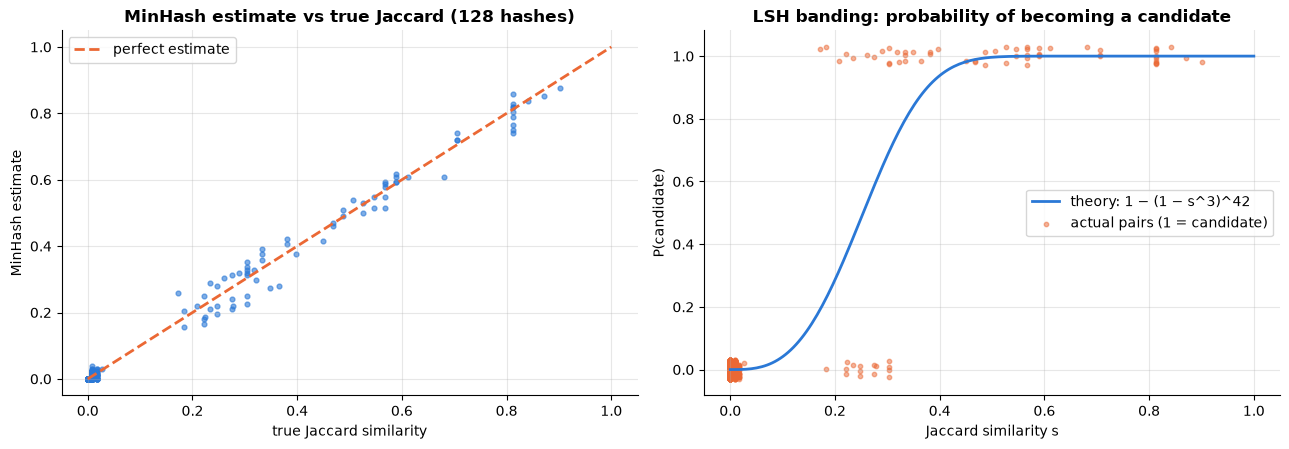

In [16]:
rng = random.Random(1)
words_pool = ("data model train test loss layer token embed vector query index score batch learn graph node edge "
              "cache shard hash bloom filter search sort merge heap stack queue tree array string bit map set").split()

def random_doc(n=60):
    return [rng.choice(words_pool) for _ in range(n)]

def mutate(doc, n_edits):
    d = doc[:]
    for _ in range(n_edits):
        d[rng.randrange(len(d))] = rng.choice(words_pool)   # replace a few words
    return d

base_docs = [random_doc() for _ in range(12)]
corpus = []                                                  # (name, words)
for i, d in enumerate(base_docs):
    corpus.append((f"doc{i}", d))
    for e in [2, 6, 15]:                                     # near-duplicates of decreasing similarity
        corpus.append((f"doc{i}_edit{e}", mutate(d, e)))

def shingles(words, w=3):
    return {zlib.crc32(" ".join(words[i:i + w]).encode()) for i in range(len(words) - w + 1)}

K, PRIME = 128, (1 << 61) - 1                                # 128 hash functions, Mersenne prime 2^61 - 1
hash_params = [(rng.randrange(1, PRIME), rng.randrange(0, PRIME)) for _ in range(K)]

def minhash(sh):
    """Signature: for each universal hash h(x) = (a x + b) mod p, the minimum over the set."""
    return np.array([min((a * x + b) % PRIME for x in sh) for a, b in hash_params], dtype=np.uint64)

sets = [shingles(w) for _, w in corpus]
sigs = [minhash(s) for s in sets]
pairs = [(i, j) for i in range(len(corpus)) for j in range(i + 1, len(corpus))]
true_j = np.array([len(sets[i] & sets[j]) / len(sets[i] | sets[j]) for i, j in pairs])
est_j = np.array([np.mean(sigs[i] == sigs[j]) for i, j in pairs])
print(f"{len(corpus)} documents, {len(pairs)} pairs | mean |MinHash estimate − true Jaccard| = {np.abs(est_j - true_j).mean():.4f}")
related = true_j > 0.1                                       # pairs that actually share content
print(f"  on the {related.sum()} related pairs (J > 0.1) alone: mean |error| = {np.abs(est_j - true_j)[related].mean():.4f}, "
      f"theory ≈ mean of sqrt(J(1-J)/K)·sqrt(2/π) = {np.mean(np.sqrt(true_j[related] * (1 - true_j[related]) / K)) * math.sqrt(2 / math.pi):.4f}")
assert np.abs(est_j - true_j).mean() < 0.03 and np.abs(est_j - true_j)[related].mean() < 0.06

# LSH banding: b bands of r rows
b, r = 42, 3                                                  # 42 bands × 3 rows = 126 of the 128 signature values
buckets = defaultdict(set)
for idx, sig in enumerate(sigs):
    for band in range(b):
        buckets[(band, sig[band * r:(band + 1) * r].tobytes())].add(idx)
candidates = {(min(p), max(p)) for bucket in buckets.values() for p in [(x, y) for x in bucket for y in bucket if x < y]}
similar = {pairs[t] for t in range(len(pairs)) if true_j[t] >= 0.5}
print(f"LSH (b = {b}, r = {r}, threshold ≈ (1/b)^(1/r) = {(1 / b) ** (1 / r):.2f}): {len(candidates)} candidate pairs out of {len(pairs)} "
      f"| recall of truly similar pairs (J ≥ 0.5): {len(similar & candidates)}/{len(similar)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(true_j, est_j, s=12, color=PALETTE[0], alpha=0.6)
ax[0].plot([0, 1], [0, 1], "--", color=PALETTE[1], label="perfect estimate")
ax[0].set(title=f"MinHash estimate vs true Jaccard ({K} hashes)", xlabel="true Jaccard similarity", ylabel="MinHash estimate"); ax[0].legend()
s = np.linspace(0, 1, 200)
ax[1].plot(s, 1 - (1 - s ** r) ** b, color=PALETTE[0], label=f"theory: 1 − (1 − s^{r})^{b}")
is_cand = np.array([p in candidates for p in pairs])
ax[1].scatter(true_j, is_cand + np.random.uniform(-0.03, 0.03, len(pairs)), s=10, color=PALETTE[1], alpha=0.5, label="actual pairs (1 = candidate)")
ax[1].set(title="LSH banding: probability of becoming a candidate", xlabel="Jaccard similarity s", ylabel="P(candidate)"); ax[1].legend(loc="center right")
plt.tight_layout(); plt.show()

**What just happened?** We built 48 documents: 12 random "originals" and, for each, three edited copies (2, 6 or 15 words replaced).
- **MinHash** with 128 universal hash functions estimated the Jaccard similarity of all 1128 pairs (left plot: points hug the diagonal). The overall average error is tiny partly because most pairs are unrelated (J ≈ 0, estimate 0); on the related pairs alone the error is a few hundredths, in line with the theoretical standard error √(J(1−J)/K), and it would shrink further with more hash functions.
- **LSH banding** (42 bands × 3 rows) produced only 57 candidate pairs instead of all 1128, yet caught **all 31** truly similar pairs (J ≥ 0.5). The right plot shows why: pairs with high similarity are candidates (y = 1), unrelated pairs are not (y = 0), following the S-curve whose threshold is about (1/b)^(1/r) ≈ 0.29. Pairs in the 0.2–0.35 range may or may not become candidates; tuning b and r moves the threshold.

This is the core of large-scale deduplication of LLM training data and of near-duplicate image/document detection. Other connections:
- **Vector databases** use LSH variants (random hyperplanes for cosine similarity) alongside graph indexes like HNSW: see [vector databases](../../13_Databases/03_vector_db/01_vector_databases.ipynb) and [semantic search](../../07_NLP/13_industry_semantic_search_engine.ipynb).
- **Caching** LLM responses or embeddings keys a dict by a stable hash (e.g. SHA-256) of the prompt; **sharding** feature stores and model replicas uses consistent hashing (section 9).
- **Dataset splitting**: hashing a user ID into train/test (`crc32(id) % 100 < 80`) keeps the split stable as data grows and prevents leakage of the same user into both sets.

---
## Recap
- A **hash table** maps keys to slots with a hash function h : U → {0..m−1}; collisions are unavoidable, so we need a **resolution strategy**. With a good hash and bounded load factor α = n/m, operations are **O(1) on average**, O(n) in the worst case.
- **Division** h(k) = k mod m needs a prime m; **multiplication** ⌊m·frac(kA)⌋ works with m = 2ᵖ; strings use **polynomial** hashes.
- Python randomises `str`/`bytes` hashes per process (SipHash, `PYTHONHASHSEED`) against hash flooding: never persist `hash()` values. Hashing is one-way; encryption is reversible.
- **Separate chaining** tolerates α ≈ 1; **open addressing** (linear, quadratic, double hashing) needs α well below 1 and **tombstones** for deletion. Linear probing suffers primary clustering; double hashing ≈ uniform hashing.
- **Rehashing** by doubling keeps inserts O(1) amortized.
- CPython's **dict**: open addressing with perturbation, compact insertion-ordered layout, ≤ 2/3 full. **set**: similar, no order.
- Hashing solves two-sum, counting, anagram grouping, consecutive sequences, subarray sums and first-unique problems in O(n).
- **Consistent hashing** moves only ~1/N of keys when servers change; **Bloom filters** answer membership with tiny memory and no false negatives; **feature hashing** and **MinHash/LSH** scale ML to huge vocabularies and corpora.

## Practice problems

**1. (Easy, conceptual)** Why is m = 1024 a bad choice for the division method h(k) = k mod m, and what would you choose instead for about 1000 slots?

<details><summary>Show solution</summary>

k mod 2¹⁰ keeps only the lowest 10 bits of k, ignoring the rest; keys that share their low bits (multiples of 8, IDs with a common suffix) all collide. Choose a **prime not close to a power of 2**, e.g. **m = 997** or 1009 (avoid 1021, which is close to 1024). Alternatively use the multiplication method, for which m = 1024 is fine.

</details>

**2. (Easy, conceptual)** A linear-probing table has load factor 0.5. Approximately how many probes does an unsuccessful search need? And at 0.9? What does this suggest about the resize threshold?

<details><summary>Show solution</summary>

½(1 + 1/(1−α)²): at α = 0.5 → ½(1 + 4) = **2.5** probes; at α = 0.9 → ½(1 + 100) = **50.5** probes. Cost explodes as α → 1, so open-addressing tables resize early (≤ 0.5–0.7; CPython's dict at 2/3).

</details>

**3. (Easy, coding)** Return True if a list contains two equal elements whose indices differ by at most k.

<details><summary>Show solution</summary>

Remember the last index of each value in a dict: O(n) time, O(min(n, distinct values)) space.
```python
def contains_nearby_duplicate(a, k):
    """True if a[i] == a[j] for some i != j with |i - j| <= k. O(n) with a dict of last positions."""
    last = {}
    for i, x in enumerate(a):
        if x in last and i - last[x] <= k:
            return True
        last[x] = i
    return False
```

</details>

**4. (Medium, coding)** Count index pairs i < j with |a[i] − a[j]| = k in O(n).

<details><summary>Show solution</summary>

Count values with a `Counter`; for k > 0 each value x pairs with every copy of x + k; for k = 0 count pairs inside each group.
```python
def count_pairs_with_difference(a, k):
    """Number of index pairs i < j with |a[i] - a[j]| == k (k >= 0). O(n) with a Counter."""
    from collections import Counter
    c = Counter(a)
    if k == 0:
        return sum(v * (v - 1) // 2 for v in c.values())
    return sum(c[x] * c[x + k] for x in c)
```

</details>

**5. (Medium, coding, interview classic)** Implement an **LRU cache** with O(1) `get(key)` and `put(key, value)`: when full, evict the least recently used key.

<details><summary>Show solution</summary>

A hash map gives O(1) lookup; a doubly linked list keeps recency order with O(1) moves. Python's `OrderedDict` is exactly that combination. (`functools.lru_cache` is the built-in decorator version.)
```python
from collections import OrderedDict

class LRUCache:
    """Least-recently-used cache: hash map + doubly linked list (OrderedDict). O(1) get and put."""
    def __init__(self, capacity):
        self.capacity, self.data = capacity, OrderedDict()
    def get(self, key):
        if key not in self.data:
            return -1
        self.data.move_to_end(key)              # mark as most recently used
        return self.data[key]
    def put(self, key, value):
        if key in self.data:
            self.data.move_to_end(key)
        self.data[key] = value
        if len(self.data) > self.capacity:
            self.data.popitem(last=False)       # evict the least recently used
```
Tested against a brute-force simulation with an explicit recency list.

</details>

**6. (Medium, conceptual)** In open addressing, why can't you delete by simply marking the slot EMPTY? Give a small example.

<details><summary>Show solution</summary>

Searches stop at the first EMPTY slot. Example with linear probing: A and B both hash to slot 3; A is stored at 3, B at 4. Delete A by emptying slot 3. A search for B starts at slot 3, sees EMPTY and reports "not found", although B is in slot 4. A **tombstone** tells the search "keep going" while still letting inserts reuse the slot. Too many tombstones slow searches, so tables rebuild themselves periodically.

</details>

**7. (Medium, conceptual)** You need to check whether each of 1 billion URLs was already crawled, with at most a 1% false-positive rate. How much memory does a Bloom filter need, and how many hash functions? What happens on a false positive?

<details><summary>Show solution</summary>

m = −n ln p / (ln 2)² = 10⁹ × 4.605 / 0.4805 ≈ **9.59 × 10⁹ bits ≈ 1.2 GB**, with k = (m/n) ln 2 ≈ **6.6 → 7** hash functions. Storing the URLs themselves would take tens to hundreds of GB. A false positive means a new URL is wrongly considered "already crawled" and skipped, which is usually acceptable for a crawler; a false negative (never happens) would cause duplicate work.

</details>

**8. (Hard, coding)** Implement **Rabin–Karp** substring search with a rolling hash: find all occurrences of a pattern in a text in expected O(n + m).

<details><summary>Show solution</summary>

Hash the pattern and every window of the text; update the window hash in O(1) by removing the leaving character and adding the entering one. Verify with a direct comparison when hashes match (collisions are possible).
```python
def rabin_karp(text, pattern, base=256, mod=1_000_000_007):
    """All start indices of pattern in text, using a rolling polynomial hash. Expected O(n + m)."""
    n, m = len(text), len(pattern)
    if m == 0 or m > n:
        return [] if m > n else list(range(n + 1))
    high = pow(base, m - 1, mod)                          # weight of the character leaving the window
    hp = ht = 0
    for i in range(m):
        hp = (hp * base + ord(pattern[i])) % mod
        ht = (ht * base + ord(text[i])) % mod
    out = []
    for i in range(n - m + 1):
        if ht == hp and text[i:i + m] == pattern:         # verify to rule out a collision
            out.append(i)
        if i + m < n:                                     # roll: remove text[i], add text[i+m]
            ht = ((ht - ord(text[i]) * high) * base + ord(text[i + m])) % mod
    return out
```
Tested against Python's regular-expression search (overlapping matches) on 3000 random strings.

</details>

## Further reading
- Cormen et al., *Introduction to Algorithms* (CLRS, 4th ed.), ch. 11 (hash tables: chaining, hash functions, universal hashing, open addressing).
- Knuth, *The Art of Computer Programming*, vol. 3, section 6.4 (hashing; the linear-probing analysis).
- Leskovec, Rajaraman & Ullman, *Mining of Massive Datasets*, ch. 3 (MinHash and LSH) and ch. 4 (Bloom filters); free at http://www.mmds.org/
- CPython source comments in `Objects/dictobject.c` (probing and compact layout): https://github.com/python/cpython/blob/main/Objects/dictobject.c
- GeeksforGeeks: [Hashing data structure](https://www.geeksforgeeks.org/hashing-data-structure/).

## Next notebook
➡️ [05 · Linked lists, stacks and queues](05_linked_lists_stacks_queues.ipynb): the module continues with linear data structures.